# Site04 / Shackleton data audit

**Status:** Local product inspection only. This notebook does not calculate Sun or Earth geometry and does not recommend a landing site.

**Product:** NASA PGDA *High-Resolution LOLA Topography for Lunar South Pole Sites* (Barker et al., 2021), Site04 Shackleton rim.

**Scientific boundary:** Values below are sampled from published GeoTIFFs in their native projected coordinates. They are not validated illumination, terrain-clear visibility, or communications results.


In [1]:
from __future__ import annotations

from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import os

import fiona
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from IPython.display import display
from rasterio.plot import plotting_extent
from shapely.geometry import Point, shape

DATA_ROOT = Path("/workspace/data/LOLA_5mpp")
SITE_DIR = DATA_ROOT / "Site04"
ACCESS_DATE_UTC = "2026-11-05"
PRODUCT_PAGE = "https://pgda.gsfc.nasa.gov/products/78"
PRODUCT_README = "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/README"
CITATION = (
    "Barker, M.K., et al. (2021), Improved LOLA Elevation Maps for South Pole Landing Sites: "
    "Error Estimates and Their Impact on Illumination Conditions, Planetary & Space Science, "
    "Volume 203, 105119, doi:10.1016/j.pss.2020.105119."
)

print("notebook_run_utc", datetime.now(timezone.utc).isoformat())
print("access_date_utc", ACCESS_DATE_UTC)
print("data_root", DATA_ROOT)
print("site_dir_exists", SITE_DIR.is_dir())


notebook_run_utc 2026-11-05T18:12:45.273988+00:00
access_date_utc 2026-11-05
data_root /workspace/data/LOLA_5mpp
site_dir_exists True


In [2]:
SOURCES = [
    {
        "file": "README",
        "role": "Product README (units, frame statement, file meanings)",
        "url": PRODUCT_README,
        "local": DATA_ROOT / "README",
        "expected_sha256": "e985a2337c9de1cd665b0ddad8b7f1fac88d65c96d1e47d1b975a91c8e53e7bd",
    },
    {
        "file": "Site04_ROIs.tgz",
        "role": "ROI shapefile archive",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_ROIs.tgz",
        "local": SITE_DIR / "Site04_ROIs.tgz",
        "expected_sha256": "8e8b788f9fdf6400f23fd36dad02138102bd1a905b4b71a5739a9a4fd8a0e07a",
    },
    {
        "file": "Site04_final_adj_5mpp_surf.tif",
        "role": "LDEM surface height Z (metres), interpolated empty pixels",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_surf.tif",
        "local": SITE_DIR / "Site04_final_adj_5mpp_surf.tif",
        "expected_sha256": "38ff70dbdf2f066c2cfa94a646c3a59d653ce7f6b4528b15fc1b43ee397ce758",
    },
    {
        "file": "Site04_final_adj_5mpp_toterr.tif",
        "role": "Total Z uncertainty (metres, stated as RMS error)",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_toterr.tif",
        "local": SITE_DIR / "Site04_final_adj_5mpp_toterr.tif",
        "expected_sha256": "416c4baa3b64def0182bb3379a1a9228482efd8ce32a39309ea8de5d0330fbe6",
    },
    {
        "file": "Site04_final_adj_5mpp_ldec.tif",
        "role": "LOLA count / number of LOLA returns in each pixel",
        "url": "https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_ldec.tif",
        "local": SITE_DIR / "Site04_final_adj_5mpp_ldec.tif",
        "expected_sha256": "fcc8c2219ae2368d5b2a1f6aec05fcf96cf725f3035ac8d80efc312a4ff29227",
    },
]


def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


rows = []
for item in SOURCES:
    path = item["local"]
    actual = sha256_file(path) if path.is_file() else None
    rows.append({
        "file": item["file"],
        "role": item["role"],
        "url": item["url"],
        "access_date_utc": ACCESS_DATE_UTC,
        "bytes": path.stat().st_size if path.is_file() else None,
        "sha256": actual,
        "checksum_matches": actual == item["expected_sha256"],
    })

inventory = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 120)
display(inventory)
print()
print("product_page", PRODUCT_PAGE)
print("citation", CITATION)
if not inventory["checksum_matches"].all():
    raise SystemExit("One or more downloaded files failed the recorded SHA-256 check.")


,file,role,url,access_date_utc,bytes,sha256,checksum_matches
0,README,"Product README (units, frame statement, file meanings)",https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/README,2026-11-05,1829,e985a2337c9de1cd665b0ddad8b7f1fac88d65c96d1e47d1b975a91c8e53e7bd,True
1,Site04_ROIs.tgz,ROI shapefile archive,https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_ROIs.tgz,2026-11-05,1712,8e8b788f9fdf6400f23fd36dad02138102bd1a905b4b71a5739a9a4fd8a0e07a,True
2,Site04_final_adj_5mpp_surf.tif,"LDEM surface height Z (metres), interpolated empty pixels",https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_surf.tif,2026-11-05,40980806,38ff70dbdf2f066c2cfa94a646c3a59d653ce7f6b4528b15fc1b43ee397ce758,True
3,Site04_final_adj_5mpp_toterr.tif,"Total Z uncertainty (metres, stated as RMS error)",https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_toterr.tif,2026-11-05,40980808,416c4baa3b64def0182bb3379a1a9228482efd8ce32a39309ea8de5d0330fbe6,True
4,Site04_final_adj_5mpp_ldec.tif,LOLA count / number of LOLA returns in each pixel,https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_ldec.tif,2026-11-05,40980740,fcc8c2219ae2368d5b2a1f6aec05fcf96cf725f3035ac8d80efc312a4ff29227,True



product_page https://pgda.gsfc.nasa.gov/products/78
citation Barker, M.K., et al. (2021), Improved LOLA Elevation Maps for South Pole Landing Sites: Error Estimates and Their Impact on Illumination Conditions, Planetary & Space Science, Volume 203, 105119, doi:10.1016/j.pss.2020.105119.


In [3]:
print("Product README (verbatim):")
print((DATA_ROOT / "README").read_text(encoding="utf-8", errors="replace"))


Product README (verbatim):
LOLA data for candidate South Pole landing sites

Each directory contains 5 m/pix GeoTiffs with south polar stereographic X/Y coords in meters, MOON_ME reference frame of ephemeris DE421.

X/Y coords follow the Generic Mapping Tools 'pixel-registered' convention (i.e., they are the centers of the pixels).

*_surf.tif : surface height Z (meters) with interpolation filling empty pix
*_ldec.tif : LDEC map, number of LOLA returns in each pixel
*_toterr.tif : Total Z uncertainty in meters (formally, the RMS error)
*_slp.tif : Slope (degrees)
*_slperr.tif : Slope uncertainty in degrees (formally, the RMS error)
Clones/ : Directory containing 100 clones of LDEM

Also in each directory are the data that make up the LDEMs:
*.xyzi - final point clouds after track adjustments and cleaning
Data format: Binary double precision floating point tables with 4 columns: X, Y, Z, RDRid
where X,Y,Z are the polar stereographic coordinates (in km) and RDRid is the LOLA RDR ID for e

In [4]:
ROI_SHP = SITE_DIR / "Site04_ROIs.shp"
ROI_PRJ = SITE_DIR / "Site04_ROIs.prj"
GMT_LINK = SITE_DIR / "Site04_ROIs.gmt"

print("shapefile_exists", ROI_SHP.is_file())
print("prj_exists", ROI_PRJ.is_file())
gmt_target = os.readlink(GMT_LINK) if GMT_LINK.is_symlink() else None
gmt_target_path = (SITE_DIR / gmt_target) if gmt_target else None
print("gmt_symlink", GMT_LINK.is_symlink())
print("gmt_target", gmt_target)
print("gmt_target_exists_beside_shapefile", bool(gmt_target_path and gmt_target_path.exists()))
print()
print("PRJ WKT:")
print(ROI_PRJ.read_text(encoding="utf-8", errors="replace"))

features = []
with fiona.open(ROI_SHP) as src:
    roi_meta = {
        "driver": src.driver,
        "crs_wkt": src.crs_wkt,
        "crs": dict(src.crs) if src.crs else None,
        "schema": src.schema,
        "bounds": src.bounds,
        "n_features": len(src),
    }
    for index, feat in enumerate(src):
        geom = shape(feat["geometry"])
        props = dict(feat["properties"])
        label = f"Site04_ROI_{index + 1:02d}"
        features.append({
            "label": label,
            "fid": index,
            "geometry_type": geom.geom_type,
            "properties": props,
            "bounds": geom.bounds,
            "area_m2": geom.area,
            "geometry": geom,
        })

print()
print("roi_layer_metadata")
print(json.dumps({k: v for k, v in roi_meta.items() if k != "schema"} | {"schema": roi_meta["schema"]}, indent=2, default=str))
print()
print("The shapefile has no name attribute. Labels below are assigned from 1-based record order.")
roi_table = pd.DataFrame([
    {
        "label": f["label"],
        "fid": f["fid"],
        "geometry_type": f["geometry_type"],
        "dbf_X": f["properties"].get("X"),
        "dbf_Y": f["properties"].get("Y"),
        "minx": f["bounds"][0],
        "miny": f["bounds"][1],
        "maxx": f["bounds"][2],
        "maxy": f["bounds"][3],
        "area_m2": f["area_m2"],
    }
    for f in features
])
display(roi_table)


shapefile_exists True
prj_exists True
gmt_symlink True
gmt_target Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt
gmt_target_exists_beside_shapefile False

PRJ WKT:
PROJCS["unknown",GEOGCS["GCS_unknown",DATUM["D_unknown",SPHEROID["unknown",1737400.0,0.0]],PRIMEM["Reference meridian",0.0],UNIT["Degree",0.0174532925199433]],PROJECTION["Stereographic_South_Pole"],PARAMETER["False_Easting",0.0],PARAMETER["False_Northing",0.0],PARAMETER["Central_Meridian",0.0],PARAMETER["Standard_Parallel_1",-90.0],UNIT["Meter",1.0]]

roi_layer_metadata
{
  "driver": "ESRI Shapefile",
  "crs_wkt": "PROJCS[\"unknown\",GEOGCS[\"unknown\",DATUM[\"unknown\",SPHEROID[\"unknown\",1737400,0]],PRIMEM[\"Reference meridian\",0],UNIT[\"Degree\",0.0174532925199433]],PROJECTION[\"Polar_Stereographic\"],PARAMETER[\"latitude_of_origin\",-90],PARAMETER[\"central_meridian\",0],PARAMETER[\"false_easting\",0],PARAMETER[\"false_northing\",0],UNIT[\"metre\",1,AUTHORITY[\"EPSG\",\"9001\"]],AXIS[\"Easting\",NORTH],AXIS[\"Nor

,label,fid,geometry_type,dbf_X,dbf_Y,minx,miny,maxx,maxy,area_m2
0,Site04_ROI_01,0,Polygon,-2812.5,-6647.5,-2842.5,-6802.5,-2782.5,-6522.5,5450.0
1,Site04_ROI_02,1,Polygon,-2757.5,-6342.5,-2792.5,-6432.5,-2712.5,-6262.5,2750.0
2,Site04_ROI_03,2,Polygon,-2677.5,-6107.5,-2702.5,-6167.5,-2642.5,-6052.5,2400.0
3,Site04_ROI_04,3,Polygon,-2657.5,-5957.5,-2687.5,-6027.5,-2627.5,-5902.5,2437.5


In [5]:
def raster_report(path: Path) -> dict:
    with rasterio.open(path) as src:
        tags = src.tags()
        band_tags = src.tags(1)
        transform = src.transform
        report = {
            "file": path.name,
            "driver": src.driver,
            "width": src.width,
            "height": src.height,
            "count": src.count,
            "dtype": src.dtypes[0],
            "nodata": src.nodata,
            "crs_wkt": src.crs.to_wkt() if src.crs else None,
            "transform": list(transform),
            "pixel_size_x": transform.a,
            "pixel_size_y": transform.e,
            "bounds": list(src.bounds),
            "units_from_crs": "metre" if src.crs and "metre" in src.crs.to_wkt().lower() else "unconfirmed_from_crs",
            "gcps_crs": src.gcps[1].to_wkt() if src.gcps and src.gcps[1] else None,
            "colorinterp": [str(item) for item in src.colorinterp],
            "descriptions": list(src.descriptions),
            "indexes": list(src.indexes),
            "is_tiled": src.is_tiled,
            "block_shapes": src.block_shapes,
            "offsets": src.offsets,
            "scales": src.scales,
            "tags": tags,
            "band_1_tags": band_tags,
            "area_or_point": tags.get("AREA_OR_POINT"),
        }
        band = src.read(1, masked=True)
        report["value_min"] = float(band.min()) if band.count() else None
        report["value_max"] = float(band.max()) if band.count() else None
        report["value_mean"] = float(band.mean()) if band.count() else None
        report["valid_pixels"] = int(band.count())
        report["nodata_pixels"] = int(np.ma.getmaskarray(band).sum())
        return report, src.crs, src.transform, src.bounds


raster_files = [
    SITE_DIR / "Site04_final_adj_5mpp_surf.tif",
    SITE_DIR / "Site04_final_adj_5mpp_toterr.tif",
    SITE_DIR / "Site04_final_adj_5mpp_ldec.tif",
]

raster_summaries = []
crs_list = []
for path in raster_files:
    report, crs, transform, bounds = raster_report(path)
    raster_summaries.append(report)
    crs_list.append((path.name, crs, transform, bounds))
    print("=" * 72)
    print(path.name)
    print(json.dumps(report, indent=2, default=str))

print()
print("CRS/transform identity across rasters:")
ref_crs, ref_transform, ref_bounds = crs_list[0][1], crs_list[0][2], crs_list[0][3]
for name, crs, transform, bounds in crs_list:
    print(name, {
        "crs_equal": crs == ref_crs,
        "transform_equal": transform == ref_transform,
        "bounds_equal": bounds == ref_bounds,
    })


Site04_final_adj_5mpp_surf.tif
{
  "file": "Site04_final_adj_5mpp_surf.tif",
  "driver": "GTiff",
  "width": 3200,
  "height": 3200,
  "count": 1,
  "dtype": "float32",
  "nodata": NaN,
  "crs_wkt": "PROJCS[\"unnamed\",GEOGCS[\"unnamed ellipse\",DATUM[\"unknown\",SPHEROID[\"unnamed\",1737400,0]],PRIMEM[\"Greenwich\",0],UNIT[\"degree\",0.0174532925199433,AUTHORITY[\"EPSG\",\"9122\"]]],PROJECTION[\"Polar_Stereographic\"],PARAMETER[\"latitude_of_origin\",-90],PARAMETER[\"central_meridian\",0],PARAMETER[\"false_easting\",0],PARAMETER[\"false_northing\",0],UNIT[\"metre\",1],AXIS[\"Easting\",NORTH],AXIS[\"Northing\",NORTH]]",
  "transform": [
    5.0,
    0.0,
    -9000.0,
    0.0,
    -5.0,
    1000.0,
    0.0,
    0.0,
    1.0
  ],
  "pixel_size_x": 5.0,
  "pixel_size_y": -5.0,
  "bounds": [
    -9000.0,
    -15000.0,
    7000.0,
    1000.0
  ],
  "units_from_crs": "metre",
  "gcps_crs": null,
  "colorinterp": [
    "1"
  ],
  "descriptions": [
    null
  ],
  "indexes": [
    1
  ],
  "is

In [6]:
# Deterministic choice: first shapefile record, labeled Site04_ROI_01.
# There is no published ROI name field in this archive.
chosen = features[0]
poly = chosen["geometry"]
sample_point = poly.representative_point()
dbf_point = Point(float(chosen["properties"]["X"]), float(chosen["properties"]["Y"]))

print("chosen_label", chosen["label"])
print("selection_rule", "first record in Site04_ROIs.shp order (FID 0), labeled Site04_ROI_01")
print("geometry_type", poly.geom_type)
print("sample_point_xy_m", (sample_point.x, sample_point.y))
print("sample_point_inside_polygon", bool(poly.contains(sample_point) or poly.covers(sample_point)))
print("dbf_xy_m", (dbf_point.x, dbf_point.y))
print("dbf_xy_inside_polygon", bool(poly.contains(dbf_point) or poly.covers(dbf_point)))
print("distance_sample_to_dbf_m", sample_point.distance(dbf_point))
print()
print("No latitude/longitude is computed. Coordinates remain in the file's projected X/Y metres.")


chosen_label Site04_ROI_01
selection_rule first record in Site04_ROIs.shp order (FID 0), labeled Site04_ROI_01
geometry_type Polygon
sample_point_xy_m (-2806.25, -6660.0)
sample_point_inside_polygon True
dbf_xy_m (-2812.5, -6647.5)
dbf_xy_inside_polygon True
distance_sample_to_dbf_m 13.975424859373685

No latitude/longitude is computed. Coordinates remain in the file's projected X/Y metres.


In [7]:
def sample_raster(path: Path, x: float, y: float) -> dict:
    with rasterio.open(path) as src:
        row, col = src.index(x, y)
        values = list(src.sample([(x, y)]))[0]
        window_ok = 0 <= row < src.height and 0 <= col < src.width
        nodata = src.nodata
        value = values[0]
        is_nodata = (nodata is not None and value == nodata) or (isinstance(value, float) and np.isnan(value))
        integer_types = {"uint8", "uint16", "uint32", "int8", "int16", "int32"}
        if is_nodata:
            stored = None
        elif src.dtypes[0] in integer_types:
            stored = int(value)
        else:
            stored = float(value)
        return {
            "file": path.name,
            "x_m": x,
            "y_m": y,
            "row": int(row),
            "col": int(col),
            "inside_raster": window_ok,
            "value": stored,
            "raw_value": value.item() if hasattr(value, "item") else value,
            "dtype": src.dtypes[0],
            "nodata": nodata,
            "is_nodata": bool(is_nodata),
        }

samples = [
    sample_raster(SITE_DIR / "Site04_final_adj_5mpp_surf.tif", sample_point.x, sample_point.y),
    sample_raster(SITE_DIR / "Site04_final_adj_5mpp_toterr.tif", sample_point.x, sample_point.y),
    sample_raster(SITE_DIR / "Site04_final_adj_5mpp_ldec.tif", sample_point.x, sample_point.y),
]
sample_df = pd.DataFrame(samples)
display(sample_df)

print()
print("Interpretation notes from the product README, not derived here:")
print("- surf.tif pixel values are surface height Z in metres, with interpolation filling empty pixels.")
print("- toterr.tif is total Z uncertainty in metres (formally RMS error).")
print("- ldec.tif is the number of LOLA returns in each pixel.")
print("- About 90% of 5 m pixels in these polar LDEMs are interpolated; a sampled height is not necessarily a measured LOLA spot.")


,file,x_m,y_m,row,col,inside_raster,value,raw_value,dtype,nodata,is_nodata
0,Site04_final_adj_5mpp_surf.tif,-2806.25,-6660.0,1532,1238,True,1728.263184,1728.263184,float32,NaN,False
1,Site04_final_adj_5mpp_toterr.tif,-2806.25,-6660.0,1532,1238,True,0.837635,0.837635,float32,NaN,False
2,Site04_final_adj_5mpp_ldec.tif,-2806.25,-6660.0,1532,1238,True,0.000000,0.000000,float32,NaN,False



Interpretation notes from the product README, not derived here:
- surf.tif pixel values are surface height Z in metres, with interpolation filling empty pixels.
- toterr.tif is total Z uncertainty in metres (formally RMS error).
- ldec.tif is the number of LOLA returns in each pixel.
- About 90% of 5 m pixels in these polar LDEMs are interpolated; a sampled height is not necessarily a measured LOLA spot.


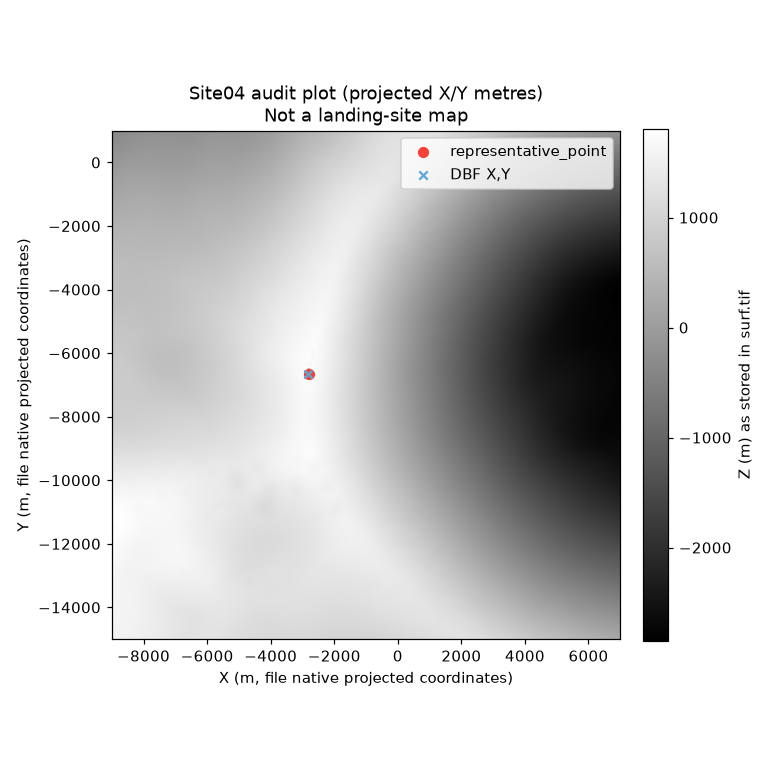

Plot uses native GeoTIFF bounds and ROI polygons. No geographic conversion was applied.


In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
with rasterio.open(SITE_DIR / "Site04_final_adj_5mpp_surf.tif") as src:
    data = src.read(1, masked=True)
    img = ax.imshow(data, cmap="gray", extent=plotting_extent(src), origin="upper")
    fig.colorbar(img, ax=ax, fraction=0.046, pad=0.04, label="Z (m) as stored in surf.tif")

for feat in features:
    geom = feat["geometry"]
    color = "#d83933" if feat["fid"] == chosen["fid"] else "#f6f6f6"
    width = 1.8 if feat["fid"] == chosen["fid"] else 0.8
    rings = [geom] if geom.geom_type == "Polygon" else list(geom.geoms)
    for part in rings:
        xs, ys = part.exterior.xy
        ax.plot(xs, ys, color=color, linewidth=width)

ax.scatter([sample_point.x], [sample_point.y], c="#f64137", s=40, zorder=5, label="representative_point")
ax.scatter([dbf_point.x], [dbf_point.y], c="#5ba8d8", s=30, marker="x", zorder=5, label="DBF X,Y")
ax.set_title("Site04 audit plot (projected X/Y metres)\nNot a landing-site map")
ax.set_xlabel("X (m, file native projected coordinates)")
ax.set_ylabel("Y (m, file native projected coordinates)")
ax.legend(loc="best")
ax.set_aspect("equal")
plt.tight_layout()
from io import BytesIO
from IPython.display import Image
buf = BytesIO()
fig.savefig(buf, format="png", dpi=110, facecolor="white")
plt.close(fig)
display(Image(data=buf.getvalue()))
print("Plot uses native GeoTIFF bounds and ROI polygons. No geographic conversion was applied.")


In [9]:
unresolved = [
    "The shapefile has no ROI name field. Site04_ROI_01 is an audit label from record order, not a published site name.",
    "Site04_ROIs.gmt points at Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt, which is not in the tgz. The illumination-threshold meaning of these polygons is therefore not confirmed from the archive contents.",
    "The product README says X/Y follow GMT pixel-registered convention (pixel centres). GDAL/rasterio typically expose a GeoTransform. AREA_OR_POINT was recorded above; a 0.5-pixel shift has not been applied or rejected.",
    "GeoTIFF and shapefile CRS WKT both use an unnamed sphere of radius 1737400 m and south-polar stereographic parameters, but they are not identical strings (Polar_Stereographic vs Stereographic_South_Pole; Greenwich vs Reference meridian). Equivalence is not proven here.",
    "The product page states MOON_ME / DE421. That frame name is not present as a GeoTIFF EPSG code. No lunar body-fixed conversion was performed.",
    "No latitude/longitude is reported. A validated body-fixed or geographic conversion needs an explicit lunar projection pipeline and an independent check.",
    "XYZI point clouds (km) were not downloaded. Consistency between km point clouds and metre GeoTIFFs is unchecked.",
    "ldec=0 vs interpolated surf values: a sampled height can be interpolated even when a polygon is inside the DEM. Interpolation vs measured-spot identity is not resolved at this point.",
    "toterr is documented as RMS height error for the LDEM, not a confidence interval on a landing recommendation.",
    "These four polygons are not claimed to be Artemis landing ellipses or challenge-required coordinates.",
]
print("Unresolved metadata / conversion questions:")
for i, item in enumerate(unresolved, start=1):
    print(f"{i}. {item}")

print()
print("Out of scope for this notebook: Sun/Earth positions, illumination windows, terrain horizons, communication links, and landing-site ranking.")


Unresolved metadata / conversion questions:
1. The shapefile has no ROI name field. Site04_ROI_01 is an audit label from record order, not a published site name.
2. Site04_ROIs.gmt points at Site04_final_adj_5mpp_01_regionProps_avgillGT070.gmt, which is not in the tgz. The illumination-threshold meaning of these polygons is therefore not confirmed from the archive contents.
3. The product README says X/Y follow GMT pixel-registered convention (pixel centres). GDAL/rasterio typically expose a GeoTransform. AREA_OR_POINT was recorded above; a 0.5-pixel shift has not been applied or rejected.
4. GeoTIFF and shapefile CRS WKT both use an unnamed sphere of radius 1737400 m and south-polar stereographic parameters, but they are not identical strings (Polar_Stereographic vs Stereographic_South_Pole; Greenwich vs Reference meridian). Equivalence is not proven here.
5. The product page states MOON_ME / DE421. That frame name is not present as a GeoTIFF EPSG code. No lunar body-fixed conversion 